# Volcano Plots

Kexin Dong

Additional volcano plots for ABE and CBE screens.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import scipy.stats
from sklearn.decomposition import PCA
from adjustText import adjust_text
from matplotlib_venn import venn2, venn3
from upsetplot import UpSet, from_indicators
import warnings
import os
warnings.filterwarnings('ignore')

# ── Global style (matching published figures) ─────────────────────────────────────────
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['text.usetex']  = False
plt.rcParams['font.family']     = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica']

blues   = sns.color_palette('Blues').as_hex()
greens  = sns.color_palette('Greens').as_hex()
reds    = sns.color_palette('Reds').as_hex()
yellows = sns.color_palette('Oranges').as_hex()
purples = sns.color_palette('Purples').as_hex()

greys = sns.color_palette('Greys').as_hex()
teals = sns.color_palette('BuPu').as_hex()
pinks = sns.color_palette('RdPu').as_hex()
browns = sns.color_palette('YlOrBr').as_hex()
BASE = '/Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/'

In [2]:
# ── Load count tables ──────────────────────────────────────────────────────
ABE_OG_COUNTS   = pd.read_csv(BASE + 'counts/og/OG_ABE_COUNTS.txt',   sep='\t')
CBE_OG_COUNTS   = pd.read_csv(BASE + 'counts/og/OG_CBE_COUNTS.txt',   sep='\t')
ABE_EPO_COUNTS  = pd.read_csv(BASE + 'counts/focused/FC_ABE_EPO_COUNTS.txt',       sep='\t')
CBE_EPO_COUNTS  = pd.read_csv(BASE + 'counts/focused/FC_CBE_EPO_COUNTS_new.txt',   sep='\t')
ABE_BC_COUNTS   = pd.read_csv(BASE + 'counts/focused/FC_ABE_BC_COUNTS.txt',        sep='\t')
CBE_BC_COUNTS   = pd.read_csv(BASE + 'counts/focused/FC_CBE_BC_COUNTS_new.txt',    sep='\t')

# ── Sample lists used in LFC-FDR (exactly mirroring LFC_FDR_calculation.ipynb) ─
# Only sample columns (no sgRNA/gene/lib annotation columns)

ABE_OG_samps = [
    'bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5',
    'meninges1','meninges2','meninges3','meninges4','meninges5',
    'spleen1','spleen2','spleen3','spleen4',
    'input_rep1','input_rep2','input_rep3',
    'd5_rep1','d5_rep2','d5_rep3',
    'd15_rep1','d15_rep2','d15_rep3',
    'plasmidlib'
]

CBE_OG_samps = [
    'bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5',
    'bonemarrow6','bonemarrow7','bonemarrow8','bonemarrow9','bonemarrow10',
    'meninges1','meninges2','meninges3','meninges4','meninges5',
    'meninges6','meninges7','meninges8','meninges9','meninges10',
    'spleen1','spleen2','spleen3','spleen4','spleen5',
    'spleen6','spleen7','spleen8','spleen9',  # spleen10 excluded
    'input_rep1','input_rep2','input_rep3',
    'd5_rep1','d5_rep2','d5_rep3',
    'd15_rep1','d15_rep2','d15_rep3',
    'plasmidlib'
]

ABE_FC_samps = [
    'bm1','bm2','bm3','bm4','bm5',
    'spleen1','spleen2','spleen3','spleen4','spleen5',
    'd15-rep1','d15-rep2','d15-rep3','d15-rep4','d15-rep5',
    'd5','input','lib'
]

# ABE BC (null): bm2 and spleen2 excluded (abnormal skewing)
ABE_BC_samps = [s for s in ABE_FC_samps if s not in ('bm2', 'spleen2')]

CBE_EPO_samps = [
    'bm1','bm3','bm4','bm6','bm7','bm9','bm10',  # bm2,5,8 excluded
    'spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10',  # spleen2,5,8 excluded
    'd15-rep1','d15-rep3','d15-rep4','d15-rep5',  # d15-rep2 excluded (abnormal skewing)
    'd5','input','lib'
]

CBE_BC_samps = [
    'bm3','bm4','bm5','bm7','bm9',  # bm1,2,6,8,10 excluded (abnormal skewing)
    'spleen3','spleen4','spleen5','spleen7','spleen9',  # spleen1,2,6,8,10 excluded (abnormal skewing)
    'd15-rep1','d15-rep2','d15-rep3','d15-rep4','d15-rep5',
    'd5','input','lib'
]

In [3]:
BASE = '/Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/'

dfs = {
    'ABE_OG':         pd.read_csv(BASE + 'LFC-FDR/ABE_OG_LFC_FDR.csv', low_memory=False),
    'CBE_OG':         pd.read_csv(BASE + 'LFC-FDR/CBE_OG_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_T0':     pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_T0_LFC_FDR.csv', low_memory=False),
    'CBE_EPO_T0':     pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_T0_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_BC':     pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_TO_BC_LFC_FDR.csv', low_memory=False),
    'CBE_EPO_BC':     pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_TO_BC_LFC_FDR.csv', low_memory=False),
    'ABE_BC_T0':      pd.read_csv(BASE + 'LFC-FDR/ABE_FC_BC_T0_LFC_FDR.csv', low_memory=False),
    'CBE_BC_T0':      pd.read_csv(BASE + 'LFC-FDR/CBE_FC_BC_T0_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_T0_FSR': pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_T0_LFC_FDR_FSR.csv', low_memory=False),
    'CBE_EPO_T0_FSR': pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_T0_LFC_FDR_FSR.csv', low_memory=False),
    'ABE_EPO_BC_FSR': pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_TO_BC_LFC_FDR_FSR.csv', low_memory=False),
    'CBE_EPO_BC_FSR': pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_TO_BC_LFC_FDR_FSR.csv', low_memory=False),
    'ABE_BC_T0_FSR':  pd.read_csv(BASE + 'LFC-FDR/ABE_FC_BC_T0_LFC_FDR_FSR.csv', low_memory=False),
    'CBE_BC_T0_FSR':  pd.read_csv(BASE + 'LFC-FDR/CBE_FC_BC_T0_LFC_FDR_FSR.csv', low_memory=False),
}

# Conditions with FDR calculated
conds_og      = ['d15', 'bm', 'spleen', 'men']
conds_focused = ['d15', 'bm', 'spleen']

# Per-replicate raw count columns per condition per screen
rep_cols = {
    'ABE_OG':         {'bm':    ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4'],
                       'men':   ['meninges1','meninges2','meninges3','meninges4','meninges5'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_OG':         {'bm':    ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4'],
                       'men':   ['meninges1','meninges2','meninges3','meninges4','meninges5'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_EPO_T0':     {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_EPO_T0':     {'bm':    ['bm1','bm3','bm4','bm6','bm7','bm9','bm10'],
                       'spleen':['spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_EPO_BC':     {'bm':    ['bm1','bm3','bm5'],
                       'spleen':['spleen1','spleen3'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_EPO_BC':     {'bm':    ['bm1','bm3','bm4','bm6','bm7','bm9','bm10'],
                       'spleen':['spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_BC_T0':      {'bm':    ['bm1','bm3','bm5'],
                       'spleen':['spleen1','spleen3'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_BC_T0':      {'bm':    ['bm1','bm3','bm4','bm5','bm7','bm8','bm9'],
                       'spleen':['spleen1','spleen3','spleen4','spleen5','spleen7','spleen8','spleen9'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    # FSR screens — d15 cols are 'd15-1','d15-2','d15-3'
    'ABE_EPO_T0_FSR': {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'CBE_EPO_T0_FSR': {'bm':    ['bm1','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'ABE_EPO_BC_FSR': {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'CBE_EPO_BC_FSR': {'bm':    ['bm1','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'ABE_BC_T0_FSR':  {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'CBE_BC_T0_FSR':  {'bm':    ['bm2','bm3','bm4','bm5'],
                       'spleen':['spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
}

# COSMIC cancer gene census
cosmic = pd.read_csv(BASE + 'source-data/Census_allSun Nov 17 02_26_47 2024.csv').fillna('Undefined')
t_dict = {
    'TSG': 'TSG', 'TSG, fusion': 'TSG',
    'Undefined': 'Undefined', 'fusion': 'Undefined',
    'oncogene': 'Oncogene',
    'oncogene, TSG': 'Oncogene/TSG', 'oncogene, TSG, fusion': 'Oncogene/TSG',
    'oncogene, fusion': 'Oncogene',
}
color_dict = {'Oncogene':'tab:red', 'Oncogene/TSG':'tab:purple',
              'TSG':'tab:blue', 'Undefined':'tab:grey'}

def add_cosmic(df):
    gene_col = 'gene_name_h' if 'gene_name_h' in df.columns else 'Gene'
    roles = []
    for v in df[gene_col]:
        sub = cosmic[cosmic['Gene Symbol'] == v]
        roles.append('Undefined' if len(sub)==0 else t_dict.get(sub['Role in Cancer'].values[0], 'Undefined'))
    df = df.copy()
    df['Role in Cancer'] = roles
    df['color'] = [color_dict[r] for r in roles]
    return df

for key in dfs:
    dfs[key] = add_cosmic(dfs[key])

print('Loaded:')
for k, v in dfs.items():
    print(f'  {k}: {len(v)} guides')


Loaded:
  ABE_OG: 1070 guides
  CBE_OG: 13242 guides
  ABE_EPO_T0: 376 guides
  CBE_EPO_T0: 1257 guides
  ABE_EPO_BC: 376 guides
  CBE_EPO_BC: 1257 guides
  ABE_BC_T0: 376 guides
  CBE_BC_T0: 1257 guides
  ABE_EPO_T0_FSR: 376 guides
  CBE_EPO_T0_FSR: 1257 guides
  ABE_EPO_BC_FSR: 376 guides
  CBE_EPO_BC_FSR: 1257 guides
  ABE_BC_T0_FSR: 376 guides
  CBE_BC_T0_FSR: 1257 guides


In [4]:
LAB_DATA_ROOT = os.environ.get("LAB_DATA_ROOT", "/Users/kexindong/Documents/GitHub/Database")
df_mutation_aacr = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_mutations_extended.txt',
                          header=0, sep='\t', comment="#", 
                          na_values=['Not Applicable', 'NA', 'NULL', '-', 'None', ''])
df_pts = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_clinical_patient.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')
df_sample = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_clinical_sample.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')
# df_sv = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_sv.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')

In [5]:
sample_id_leukemia = df_sample[df_sample['CANCER_TYPE'].isin(['B-Lymphoblastic Leukemia/Lymphoma'])]['SAMPLE_ID'].unique()
df_mutation_aacr_leukemia = df_mutation_aacr[df_mutation_aacr['Tumor_Sample_Barcode'].isin(sample_id_leukemia)].reset_index(drop=True)
df_mutation_aacr_leukemia = df_mutation_aacr_leukemia[df_mutation_aacr_leukemia['Variant_Type']== 'SNP'].reset_index(drop=True)
df_mutation_aacr_leukemia = df_mutation_aacr_leukemia[df_mutation_aacr_leukemia['Center']== 'MSK'].reset_index(drop=True)
df_mutation_aacr_leukemia

,Hugo_Symbol,Entrez_Gene_Id,Center,NCBI_Build,Chromosome,Start_Position,End_Position,Strand,Consequence,Variant_Classification,...,FILTER,Polyphen_Prediction,Polyphen_Score,SIFT_Prediction,SIFT_Score,SWISSPROT,n_depth,t_depth,Annotation_Status,mutationInCis_Flag
0,NRAS,4893.0,MSK,GRCh37,1,115258747,115258747,+,missense_variant,Missense_Mutation,...,PASS,benign,0.339,deleterious,0.00,NaN,1450.0,1323.0,SUCCESS,False
1,HGF,3082.0,MSK,GRCh37,7,81381472,81381472,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.998,deleterious,0.00,NaN,278.0,431.0,SUCCESS,False
2,SOX2,6657.0,MSK,GRCh37,3,181430972,181430972,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.953,deleterious,0.00,NaN,1328.0,1135.0,SUCCESS,False
3,KRAS,3845.0,MSK,GRCh37,12,25398285,25398285,+,missense_variant,Missense_Mutation,...,PASS,possibly_damaging,0.497,deleterious,0.03,NaN,828.0,723.0,SUCCESS,False
4,ATRX,546.0,MSK,GRCh37,X,76889169,76889169,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.982,deleterious,0.00,NaN,851.0,339.0,SUCCESS,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1511,KIT,3815.0,MSK,GRCh37,4,55594093,55594093,+,"missense_variant,splice_region_variant",Missense_Mutation,...,PASS,probably_damaging,0.922,tolerated,0.19,NaN,761.0,753.0,SUCCESS,False
1512,SMARCA4,6597.0,MSK,GRCh37,19,11105660,11105660,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.999,deleterious,0.00,NaN,808.0,887.0,SUCCESS,False
1513,NRAS,4893.0,MSK,GRCh37,1,115258744,115258744,+,missense_variant,Missense_Mutation,...,PASS,benign,0.323,deleterious,0.05,NaN,808.0,562.0,SUCCESS,False
1514,MSH6,2956.0,MSK,GRCh37,2,48028296,48028296,+,splice_donor_variant,Splice_Site,...,PASS,NaN,NaN,NaN,NaN,NaN,388.0,494.0,SUCCESS,False


In [6]:
df_leukemia = df_mutation_aacr_leukemia[['Hugo_Symbol', 'Entrez_Gene_Id', 'Chromosome', 'Start_Position', 'End_Position', 'Reference_Allele', 'Tumor_Seq_Allele2', 'Variant_Type', 'Variant_Classification', 'Strand', 'Tumor_Sample_Barcode']].drop_duplicates().reset_index(drop=True).copy()
df_leukemia = df_leukemia[df_leukemia['Chromosome']!= 'MT'].reset_index(drop=True)
df_leukemia = df_leukemia[['Hugo_Symbol', 'Entrez_Gene_Id', 'Chromosome', 'Start_Position', 'End_Position', 'Reference_Allele', 'Tumor_Seq_Allele2', 'Variant_Type', 'Variant_Classification', 'Strand']].value_counts().reset_index()

In [7]:
df_leukemia.reset_index(drop=True)
df_leukemia.columns = df_leukemia.columns[:-1].tolist() + ['pts_count']
df_leukemia

,Hugo_Symbol,Entrez_Gene_Id,Chromosome,Start_Position,End_Position,Reference_Allele,Tumor_Seq_Allele2,Variant_Type,Variant_Classification,Strand,pts_count
0,MYD88,4615.0,3,38182641,38182641,T,C,SNP,Missense_Mutation,+,26
1,NRAS,4893.0,1,115258747,115258747,C,T,SNP,Missense_Mutation,+,16
2,ABL1,25.0,9,133748283,133748283,C,T,SNP,Missense_Mutation,+,10
3,JAK2,3717.0,9,5078360,5078360,A,G,SNP,Missense_Mutation,+,10
4,KRAS,3845.0,12,25398284,25398284,C,T,SNP,Missense_Mutation,+,9
...,...,...,...,...,...,...,...,...,...,...,...
1170,HDAC4,9759.0,2,240098156,240098156,C,T,SNP,Missense_Mutation,+,1
1171,HDAC4,9759.0,2,240111564,240111564,G,A,SNP,Missense_Mutation,+,1
1172,HDAC7,51564.0,12,48185368,48185368,C,T,SNP,Splice_Site,+,1
1173,HDAC7,51564.0,12,48185659,48185659,A,T,SNP,Missense_Mutation,+,1


2 [-0.00236402 -0.9354307 ]
3 [-0.37590763 -0.21714975]
0 [-0.22273851  0.49129749]
5 [-0.5514996 -0.2599516]
1 [-0.71735741  0.59874876]
6 [-0.9272262   0.71796354]
5 [-0.65326351 -0.83108975]
6 [-0.83926692 -0.03697998]
4 [ 0.51248024 -0.34672441]
5 [-0.6389525   0.06286676]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


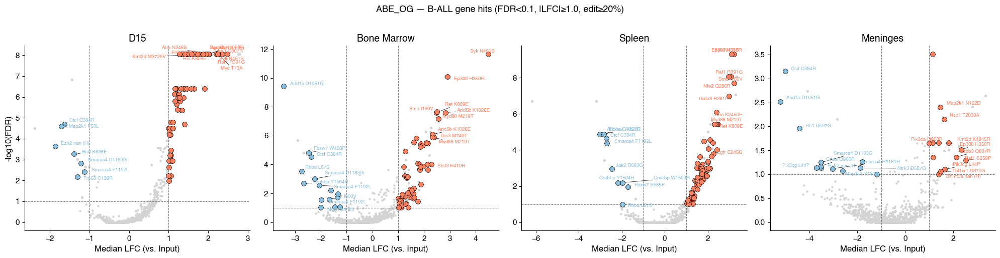

Saved: figures_final_volcano_b-all/volcano_leukemia_ABE_OG.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


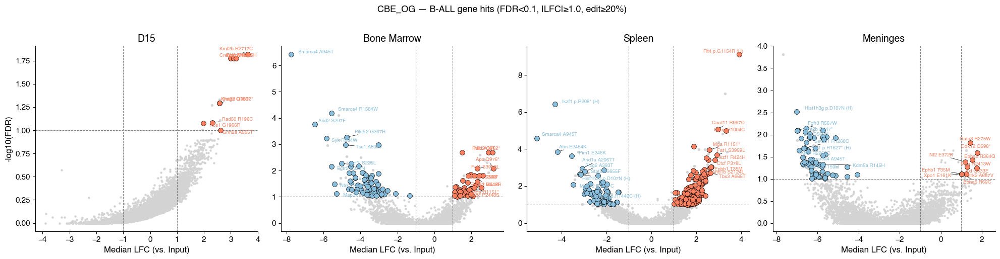

Saved: figures_final_volcano_b-all/volcano_leukemia_CBE_OG.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


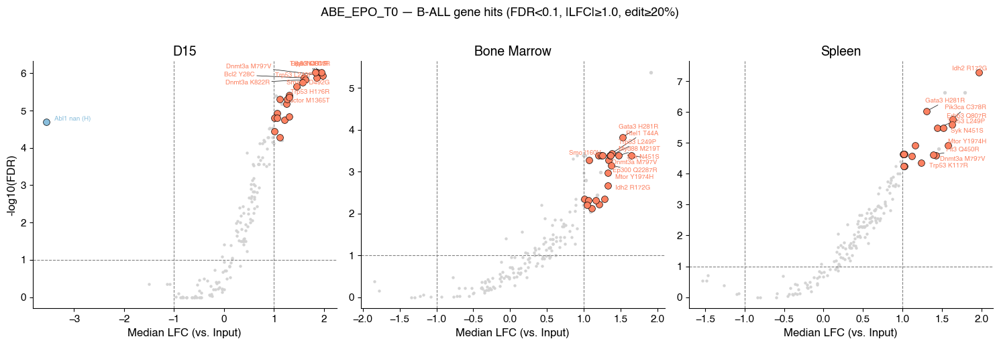

Saved: figures_final_volcano_b-all/volcano_leukemia_ABE_EPO_T0.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


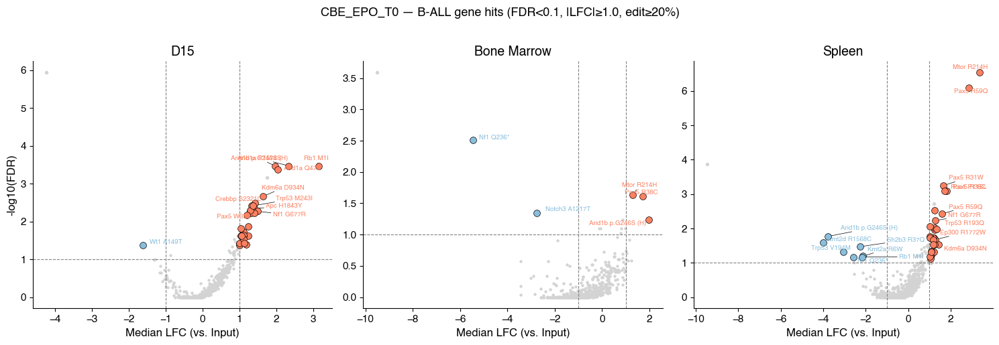

Saved: figures_final_volcano_b-all/volcano_leukemia_CBE_EPO_T0.pdf
2 [-0.16913335  0.58673677]
5 [ 0.41359386 -0.96377728]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


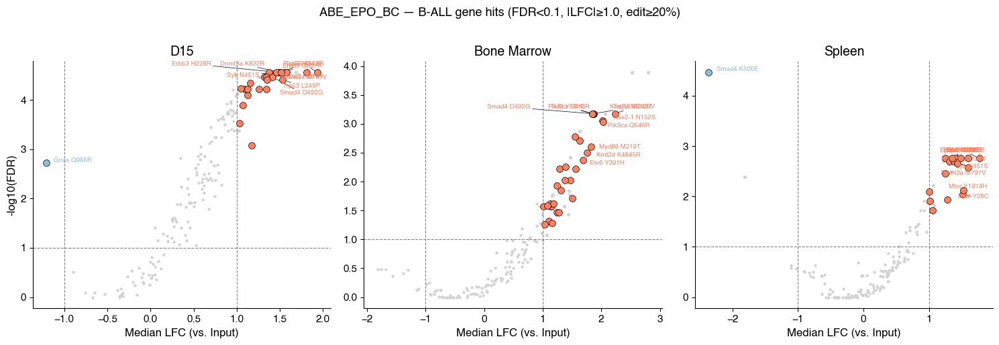

Saved: figures_final_volcano_b-all/volcano_leukemia_ABE_EPO_BC.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


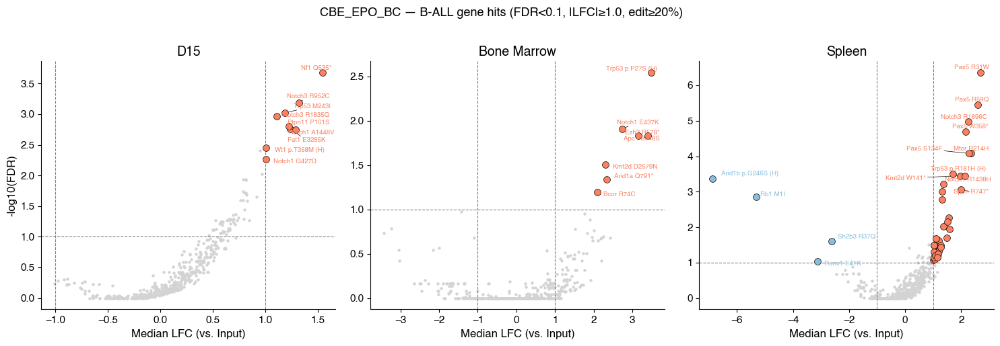

Saved: figures_final_volcano_b-all/volcano_leukemia_CBE_EPO_BC.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


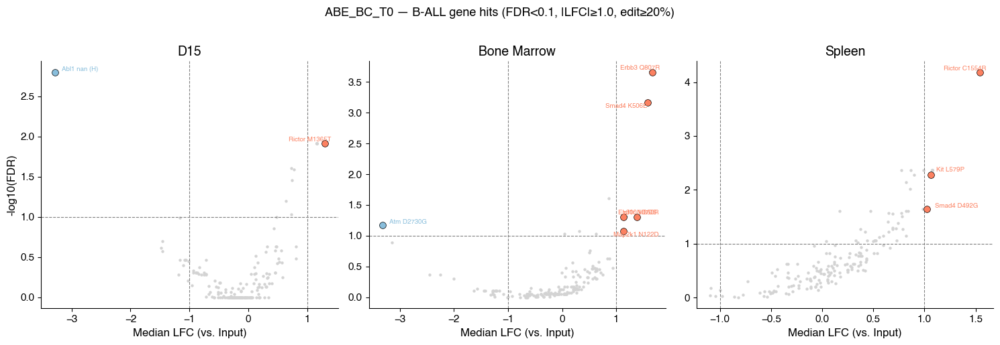

Saved: figures_final_volcano_b-all/volcano_leukemia_ABE_BC_T0.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


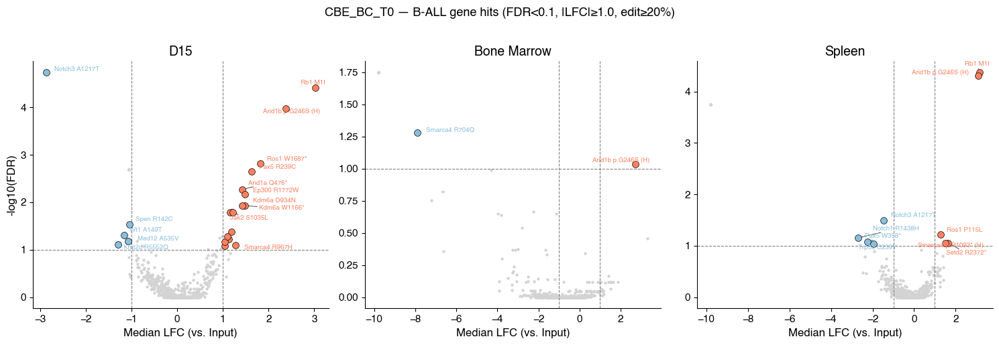

Saved: figures_final_volcano_b-all/volcano_leukemia_CBE_BC_T0.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


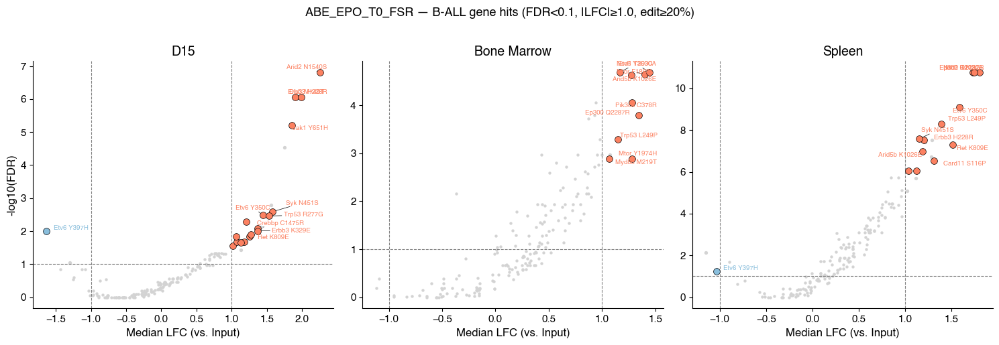

Saved: figures_final_volcano_b-all/volcano_leukemia_ABE_EPO_T0_FSR.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


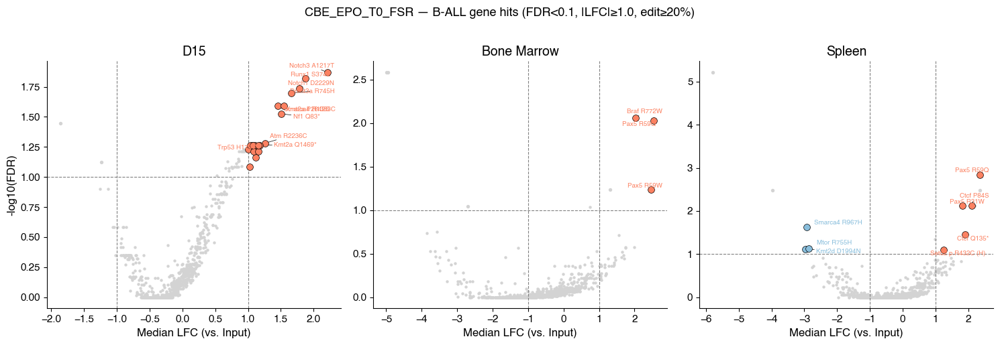

Saved: figures_final_volcano_b-all/volcano_leukemia_CBE_EPO_T0_FSR.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


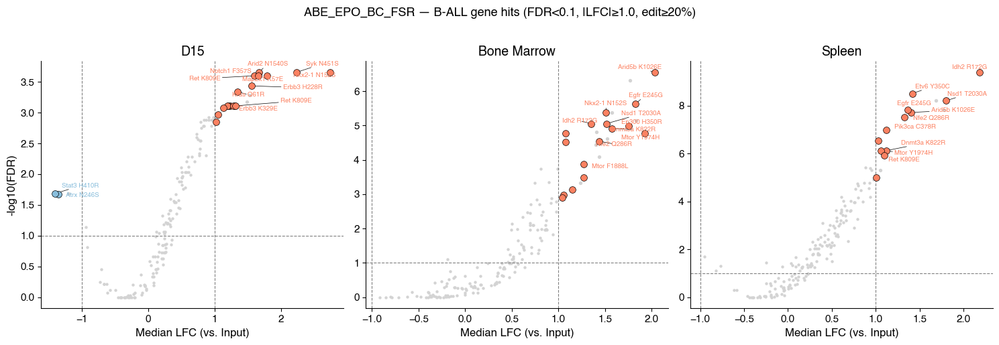

Saved: figures_final_volcano_b-all/volcano_leukemia_ABE_EPO_BC_FSR.pdf
2 [0.20949844 0.51799181]
3 [ 0.94626225 -0.18490755]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


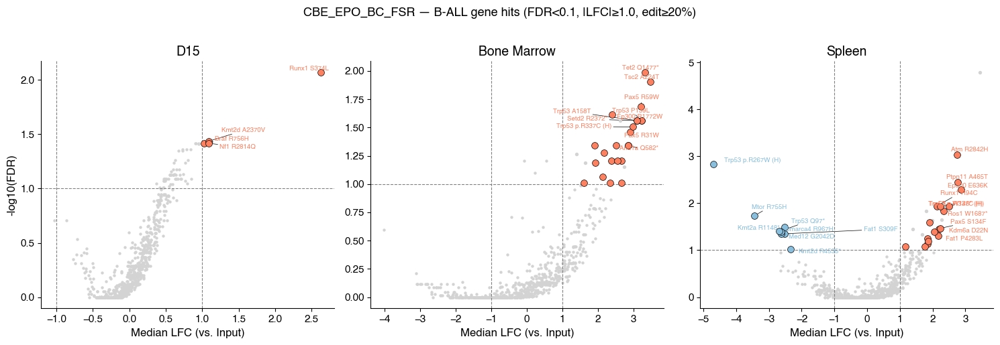

Saved: figures_final_volcano_b-all/volcano_leukemia_CBE_EPO_BC_FSR.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


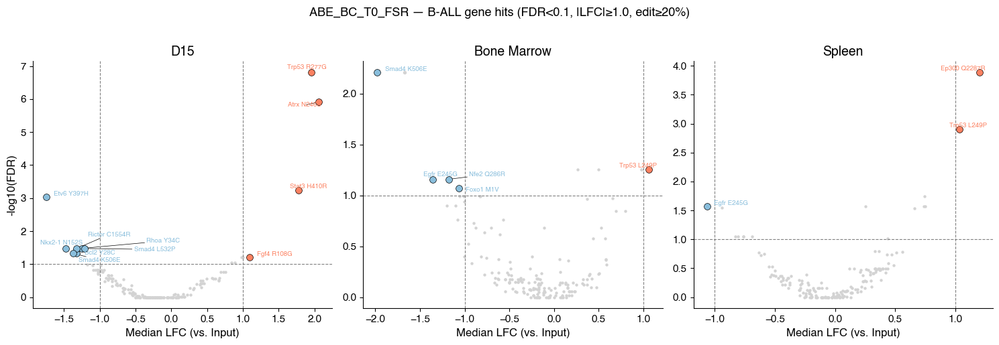

Saved: figures_final_volcano_b-all/volcano_leukemia_ABE_BC_T0_FSR.pdf


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


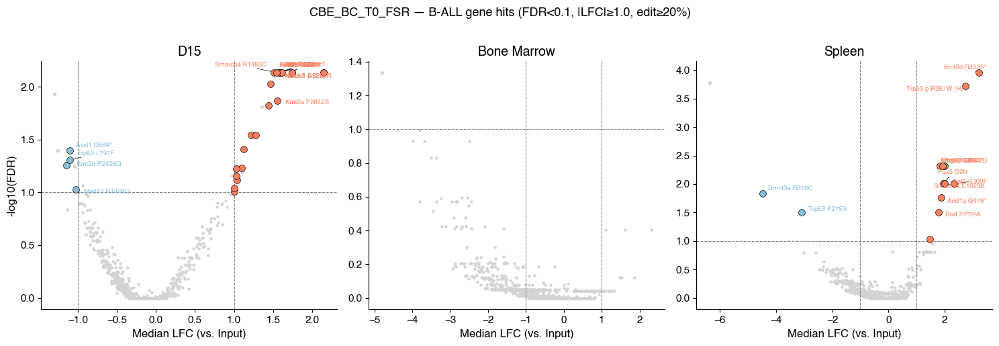

Saved: figures_final_volcano_b-all/volcano_leukemia_CBE_BC_T0_FSR.pdf


In [8]:
min_edit     = 20
min_input_og = 10
min_input_fc = 100
FDR_cutoff   = 0.1
LFC_cutoff   = 1.0

leukemia_genes = set(df_leukemia['Hugo_Symbol'].dropna().unique())
conditions_emp = ['d15', 'bm', 'spleen', 'men']
titles         = ['D15', 'Bone Marrow', 'Spleen', 'Meninges']

def volcano_leukemia(screen_key, out_filename, conditions=conditions_emp, titles=titles):
    df = dfs[screen_key]
    min_input = min_input_og if 'OG' in screen_key else min_input_fc
    conds_avail = [c for c in conditions if f'LFC_median_{c}' in df.columns]
    titles_avail = [t for c, t in zip(conditions, titles) if c in conds_avail]

    targ = df[
        (df['classification'] == 'targeting guide') &
        (df['Input_median'] >= min_input)
    ].copy()

    edit_col = 'target_base_edit_perc_d5'
    if edit_col in targ.columns:
        targ = targ[targ[edit_col] >= min_edit]

    fig, axes = plt.subplots(1, len(conds_avail), figsize=(5 * len(conds_avail), 5))
    if len(conds_avail) == 1:
        axes = [axes]

    for ax, cond, title in zip(axes, conds_avail, titles_avail):
        lfc_col = f'LFC_median_{cond}'
        fdr_col = f'FDR_{cond}_fishers'
        if fdr_col not in targ.columns:
            ax.set_visible(False)
            continue

        sub = targ[[lfc_col, fdr_col, 'gene_name_h', 'gene_name_m_corrected', 'HGVSp_m', 'HGVSp_h']].dropna(subset=[lfc_col, fdr_col]).copy()
        sub['neg_log10_fdr'] = -np.log10(sub[fdr_col].clip(lower=1e-300))

        is_hit     = (sub[fdr_col] < FDR_cutoff) & (sub[lfc_col].abs() >= LFC_cutoff)
        is_enrich  = is_hit & (sub[lfc_col] > 0)
        is_deplete = is_hit & (sub[lfc_col] < 0)
        is_leuk    = is_hit & sub['gene_name_h'].isin(leukemia_genes)

        ax.scatter(sub.loc[~is_hit, lfc_col], sub.loc[~is_hit, 'neg_log10_fdr'],
                   color='lightgrey', s=10, linewidths=0, zorder=1)
        ax.scatter(sub.loc[is_hit & ~is_leuk, lfc_col], sub.loc[is_hit & ~is_leuk, 'neg_log10_fdr'],
                   color='lightgrey', s=15, linewidths=0, zorder=2)
        ax.scatter(sub.loc[is_leuk & is_enrich, lfc_col], sub.loc[is_leuk & is_enrich, 'neg_log10_fdr'],
                   color=reds[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)
        ax.scatter(sub.loc[is_leuk & is_deplete, lfc_col], sub.loc[is_leuk & is_deplete, 'neg_log10_fdr'],
                   color=blues[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)

        ax.axhline(-np.log10(FDR_cutoff), color='grey', lw=0.8, ls='--')
        ax.axvline( LFC_cutoff, color='grey', lw=0.8, ls='--')
        ax.axvline(-LFC_cutoff, color='grey', lw=0.8, ls='--')

        leuk_enrich  = sub[is_leuk & is_enrich].sort_values(lfc_col, ascending=False).head(10)
        leuk_deplete = sub[is_leuk & is_deplete].sort_values(lfc_col, ascending=True).head(10)
        texts = []
        for _, row in pd.concat([leuk_enrich, leuk_deplete]).iterrows():
            mut = row['HGVSp_m']
            if pd.isna(mut) or mut in ('Non-coding', 'Not calculated (legacy)'):
                mut = str(row['HGVSp_h']) + ' (H)'
            color = reds[2] if row[lfc_col] > 0 else blues[2]
            texts.append(ax.text(row[lfc_col], row['neg_log10_fdr'],
                                 f"{row['gene_name_m_corrected']} {mut}",
                                 fontsize=7, color=color, zorder=5))
        if texts:
            adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

        ax.set_title(title, fontsize=14)
        ax.set_xlabel('Median LFC (vs. Input)', fontsize=12)
        if ax is axes[0]:
            ax.set_ylabel('-log10(FDR)', fontsize=12)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='both', which='major', labelsize=11)

    fig.suptitle(f'{screen_key} — B-ALL gene hits (FDR<{FDR_cutoff}, |LFC|≥{LFC_cutoff}, edit≥{min_edit}%)',
                 fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig(BASE + f'figures_final_volcano_b-all/{out_filename}', bbox_inches='tight')
    plt.show()
    print(f'Saved: figures_final_volcano_b-all/{out_filename}')

# ── Run for all screens ───────────────────────────────────────────────────
for key in dfs:
    volcano_leukemia(key, out_filename=f'volcano_leukemia_{key}.pdf')


In [ ]:
df = dfs['ABE_EPO_T0']

min_input = 100
FDR_cutoff = 0.1
LFC_cutoff = 1.0
edit_cutoff = 20

targ = df[
    (df['classification'] == 'targeting guide') &
    (df['Input_median'] >= min_input)
].copy()

# Apply editing filter (any condition)
edit_cols = [c for c in targ.columns if c.startswith('target_base_edit_perc_')]
sensor_cols = [c for c in targ.columns if c.startswith('sensor_reads_')]
if edit_cols:   targ = targ[(targ[edit_cols]   >= edit_cutoff).any(axis=1)]
if sensor_cols: targ = targ[(targ[sensor_cols] >= 100).any(axis=1)]

# Depleter hits: FDR<0.1 and LFC < -1 in any condition
conditions = ['d15', 'bm', 'spleen']
depleters = []
for cond in conditions:
    lfc_col = f'LFC_median_{cond}'
    fdr_col = f'FDR_{cond}_fishers'
    if lfc_col not in targ.columns or fdr_col not in targ.columns:
        continue
    mask = (targ[fdr_col] < FDR_cutoff) & (targ[lfc_col] <= -LFC_cutoff)
    hits = targ[mask].copy()
    hits['hit_condition'] = cond
    depleters.append(hits)

depleter_hits = pd.concat(depleters).drop_duplicates(subset='gRNA_id')
display(depleter_hits[['gRNA_id', 'gene_name_m_corrected', 'gene_name_h', 'HGVSp_m', 'HGVSp_h',
                        'LFC_median_d15', 'FDR_d15_fishers',
                        'LFC_median_bm',  'FDR_bm_fishers',
                        'LFC_median_spleen', 'FDR_spleen_fishers',
                        'hit_condition']])


,gRNA_id,gene_name_m_corrected,gene_name_h,HGVSp_m,HGVSp_h,LFC_median_d15,FDR_d15_fishers,LFC_median_bm,FDR_bm_fishers,LFC_median_spleen,FDR_spleen_fishers,hit_condition
0,gRNA_2,Abl1,ABL1,Non-coding,NaN,-3.550198,0.000021,-0.003467,0.190944,-0.592857,0.767563,d15


In [ ]:
df_library = pd.read_csv(BASE + 'MBESv2_focused.csv', index_col=0)
display(df_library.head())


,gRNA_id,mutation_idx,gene_name_h,gene_id_h,tx_id_h,chr_h,exon_num_h,strand_h,match,start_h,...,classification,Genome_version,Hamming_BC,Pool,gRNA_oligo,gene_name_m_corrected,legacy,newly_added,level_0,PAM_NGN
0,gRNA_2,0,ABL1,ENSG00000097007.13,ENST00000318560.5,chr9,11.0,+,True,133730186.0,...,targeting guide,GrCm39,CCTATACCCGAATCT,F1-R1,AGGCACTTGCTCGTACGACGAGCGTACACGTCTCACACCGTTCTAA...,Abl1,False,False,NaN,GGG
1,gRNA_4,3,ABL1,ENSG00000097007.13,ENST00000318560.5,chr9,11.0,+,True,133760819.0,...,targeting guide,GrCm39,CCGGAGTAGGTCCTC,F2-R2,GTGTAACCCGTAGGGCACCTAGCGTACACGTCTCACACCGGCTCTG...,Abl1,False,False,NaN,GGC
2,gRNA_19,15,ABL1,ENSG00000097007.13,ENST00000318560.5,chr9,11.0,+,True,133759395.0,...,targeting guide,GrCm39,GGTCGGATCACATAA,F2-R2,GTGTAACCCGTAGGGCACCTAGCGTACACGTCTCACACCGTGCTTC...,Abl1,False,False,NaN,CGG
3,gRNA_21,17,ABL1,ENSG00000097007.13,ENST00000318560.5,chr9,11.0,+,True,133759832.0,...,targeting guide,GrCm39,AAGACATACGCAAAG,F2-R2,GTGTAACCCGTAGGGCACCTAGCGTACACGTCTCACACCGGAGGCC...,Abl1,False,False,NaN,GGA
4,gRNA_85,68,AKT1,ENSG00000142208.11,ENST00000349310.3,chr14,13.0,-,True,105239419.0,...,targeting guide,GrCm39,TGCAAGCATTCATGT,F1-R1,AGGCACTTGCTCGTACGACGAGCGTACACGTCTCACACCGAGGACA...,Akt1,False,False,NaN,TGC


#### empirical FPR calibration

In [ ]:
# ── FPR Analysis ─────────────────────────────────────────────────────────────

def compute_fpr_table(df, conditions, effect='median', fdr_method='fishers',
                      fdr_cutoff=0.1, lfc_cutoff=1.0, is_og=True):
    """FPR = # control guides called as hits / total control guides, per condition."""
    rows = []
    for cond in conditions:
        lfc_col = f'LFC_{effect}_{cond}'
        fdr_col = f'FDR_{cond}_{fdr_method}'
        if lfc_col not in df.columns or fdr_col not in df.columns:
            continue
        ctrl = df[df['classification'].isin(['non-targeting control', 'safe-targeting control'])].copy()
        ctrl = ctrl.dropna(subset=[lfc_col, fdr_col])
        total = len(ctrl)
        if total == 0:
            continue
        is_hit = (ctrl[fdr_col] < fdr_cutoff) & (ctrl[lfc_col].abs() >= lfc_cutoff)
        n_fp = is_hit.sum()
        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15'}.get(cond, cond)
        rows.append({'condition': cond_label, 'n_controls': total,
                     'n_FP': n_fp, 'FPR': n_fp / total})
    return pd.DataFrame(rows)

conditions_emp = ['d15', 'bm', 'spleen', 'men']

fpr_abe = compute_fpr_table(dfs['ABE_OG'], conditions_emp, is_og=True)
fpr_cbe = compute_fpr_table(dfs['CBE_OG'], conditions_emp, is_og=True)

print("=== ABE OG FPR ===")
print(fpr_abe.to_string(index=False))
print("\n=== CBE OG FPR ===")
print(fpr_cbe.to_string(index=False))


=== ABE OG FPR ===
  condition  n_controls  n_FP      FPR
        D15          36     0 0.000000
Bone Marrow          36     1 0.027778
     Spleen          36     2 0.055556
   Meninges          36     0 0.000000

=== CBE OG FPR ===
  condition  n_controls  n_FP      FPR
        D15         436     1 0.002294
Bone Marrow         436    37 0.084862
     Spleen         436    53 0.121560
   Meninges         436    23 0.052752


In [ ]:
def volcano_plot(df, screen_name, conditions,
                 effect='median', fdr_method='fishers',
                 edit_cutoff=20,
                 fdr_cutoff=0.1, lfc_cutoff=1.0,
                 is_og=False, show_empirical_fpr=True, empirical_fpr_target=0.05):

    min_sensor  = 10 if is_og else 100
    min_input   = 10 if is_og else 100

    n = len(conditions)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1: axes = [axes]

    _cmap = plt.cm.Blues

    input_ok = df['Input_median'] >= min_input if 'Input_median' in df.columns else pd.Series(True, index=df.index)

    for k, cond in enumerate(conditions):
        lfc_col   = f'LFC_{effect}_{cond}'
        fdr_col   = f'FDR_{cond}_{fdr_method}'
        reads_col = f'sensor_reads_{cond}'
        edit_col  = f'target_base_edit_perc_{cond}'
        if lfc_col not in df.columns or fdr_col not in df.columns:
            continue
        ax = axes[k]

        if reads_col in df.columns and edit_col in df.columns:
            guide_ok = input_ok & (df[reads_col] >= min_sensor) & (df[edit_col] >= edit_cutoff)
        else:
            guide_ok = input_ok

        targ  = df[(df['classification'] == 'targeting guide') & guide_ok].copy()
        trunc = df[(df['classification'] == 'essential truncation guide') & guide_ok].copy()
        ntc   = df[df['classification'] == 'non-targeting control'].copy()
        stc   = df[df['classification'] == 'safe-targeting control'].copy()
        ctrl  = pd.concat([ntc, stc]).dropna(subset=[lfc_col, fdr_col])

        # ── Compute empirical FDR threshold where FPR <= target ──────────────
        empirical_fdr_thresh = None
        if show_empirical_fpr and len(ctrl) > 0:
            total_ctrl = len(ctrl)
            # Sweep FDR thresholds from tight to loose; find tightest where FPR <= target
            fdr_sweep = np.logspace(-4, 0, 200)
            for fdr_t in fdr_sweep:
                fp = ((ctrl[fdr_col] < fdr_t) & (ctrl[lfc_col].abs() >= lfc_cutoff)).sum()
                if fp / total_ctrl <= empirical_fpr_target:
                    empirical_fdr_thresh = fdr_t

        # ── Scatter plots ─────────────────────────────────────────────────────
        if len(targ):
            neg_log_fdr = -np.log10(targ[fdr_col].clip(lower=1e-300))
            vmax = max(neg_log_fdr.max(), -np.log10(fdr_cutoff) * 2)
            norm = plt.Normalize(vmin=0, vmax=vmax)
            colors_targ = _cmap(norm(neg_log_fdr))
            ax.scatter(targ[lfc_col], neg_log_fdr,
                       c=colors_targ, s=20, alpha=0.6,
                       linewidths=0, edgecolors='none')

        for ctrl_df in [ntc, stc]:
            if len(ctrl_df):
                yvals = -np.log10(ctrl_df[fdr_col].clip(lower=1e-300))
                ax.scatter(ctrl_df[lfc_col], yvals,
                           c='#e41a1c', s=30, alpha=0.7,
                           linewidths=0, edgecolors='none', zorder=3)

        if len(trunc):
            yvals = -np.log10(trunc[fdr_col].clip(lower=1e-300))
            ax.scatter(trunc[lfc_col], yvals,
                       c='#ffcc00', s=30, alpha=0.8,
                       linewidths=0, edgecolors='none', zorder=3)

        # ── Threshold lines ───────────────────────────────────────────────────
        ax.axhline(-np.log10(fdr_cutoff), color='black', linestyle='--', linewidth=0.8,
                   label=f'FDR={fdr_cutoff} (nominal)')
        if empirical_fdr_thresh is not None:
            ax.axhline(-np.log10(empirical_fdr_thresh), color='orange', linestyle='--', linewidth=0.8,
                       label=f'FDR={empirical_fdr_thresh:.3f} (FPR≤{empirical_fpr_target*100:.0f}%)')
        ax.axvline( lfc_cutoff, color='grey', linestyle=':', linewidth=0.8)
        ax.axvline(-lfc_cutoff, color='grey', linestyle=':', linewidth=0.8)

        n_hits = int(((targ[fdr_col] < fdr_cutoff) & (targ[lfc_col].abs() > lfc_cutoff)).sum()) if len(targ) else 0
        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15'}.get(cond, cond)
        ax.set_title(f'{cond_label}  (n={n_hits} hits)', fontsize=16)
        ax.set_xlabel(f'{effect.replace("_"," ").title()} LFC', fontsize=16)
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(labelsize=16, direction='out', length=6, width=1)
        if k == 0:
            ax.set_ylabel(f'-log10(FDR {fdr_method})', fontsize=16)
        ax.legend(fontsize=9, loc='upper left')

    min_s_label = f'sensor>={min_sensor}, edit>={edit_cutoff}%, input>={min_input}'
    fig.suptitle(f'{screen_name}  |  {effect}  |  {fdr_method}  |  {min_s_label}', fontsize=16, y=1.01)
    fig.tight_layout()
    return fig


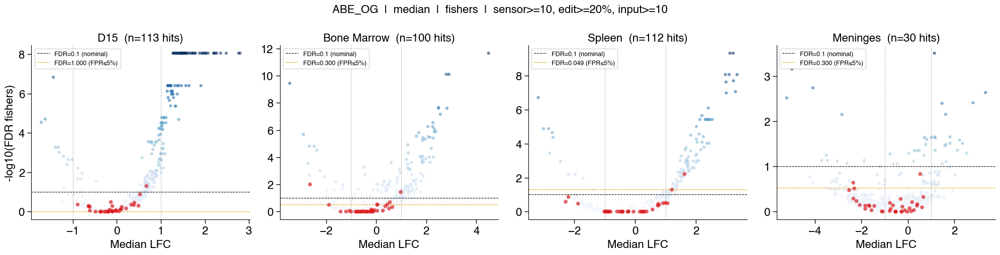

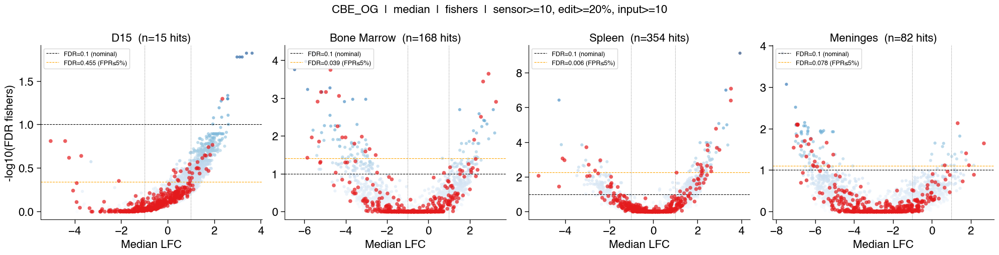

In [ ]:
fig = volcano_plot(dfs['ABE_OG'], 'ABE_OG', conditions_emp, is_og=True)
plt.show()
fig = volcano_plot(dfs['CBE_OG'], 'CBE_OG', conditions_emp, is_og=True)
plt.show()


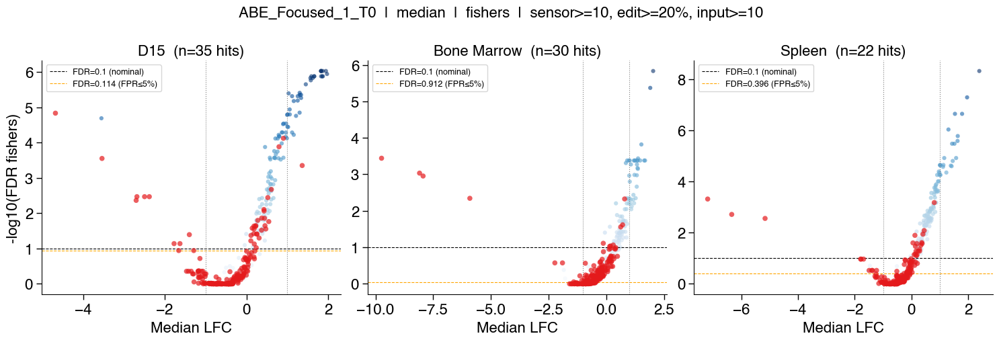

In [ ]:
fig = volcano_plot(dfs['ABE_EPO_T0'], 'ABE_Focused_1_T0', conds_focused, is_og=True)
plt.show()


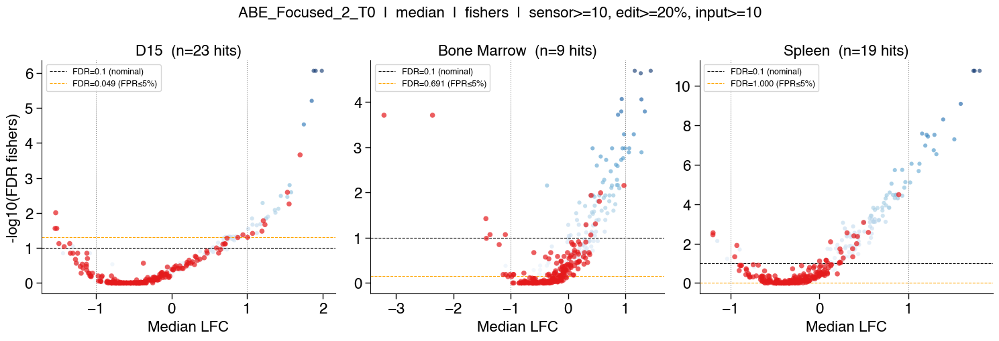

In [ ]:
fig = volcano_plot(dfs['ABE_EPO_T0_FSR'], 'ABE_Focused_2_T0', conds_focused, is_og=True)
plt.show()


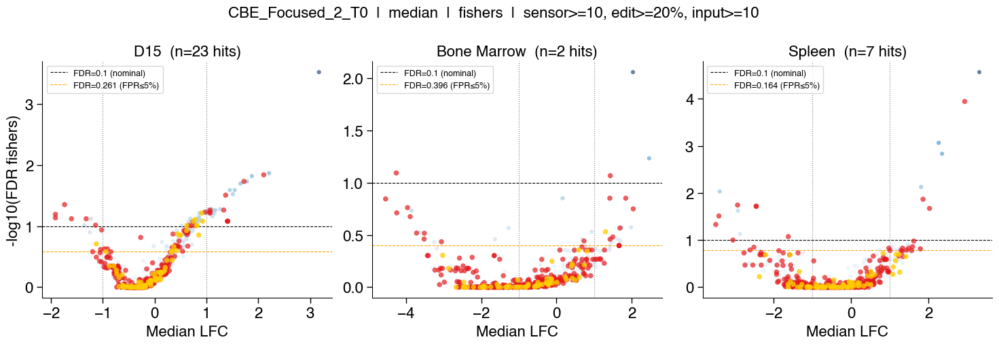

In [ ]:
fig = volcano_plot(dfs['CBE_EPO_T0_FSR'], 'CBE_Focused_2_T0', conds_focused, is_og=True)
plt.show()


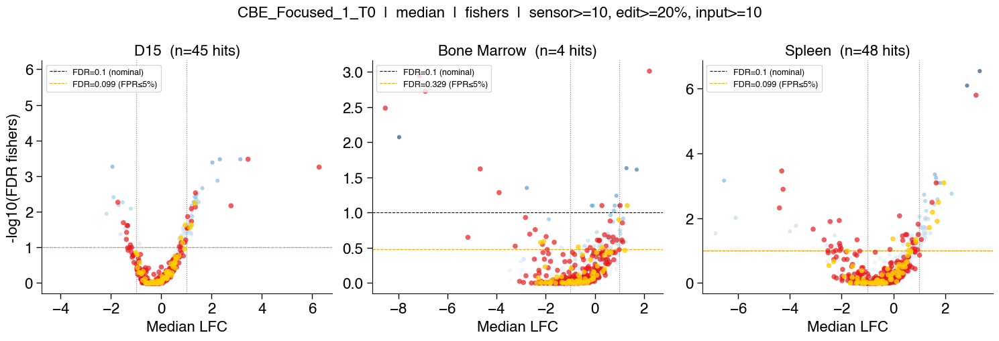

In [ ]:
fig = volcano_plot(dfs['CBE_EPO_T0'], 'CBE_Focused_1_T0', conds_focused, is_og=True)
plt.show()


## Additional volcano plots (not filtered, everything)

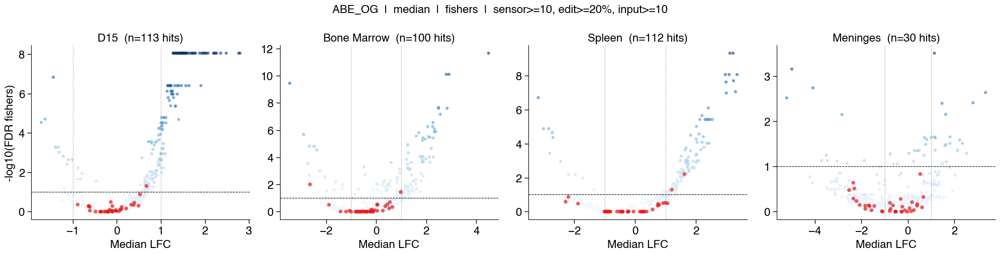

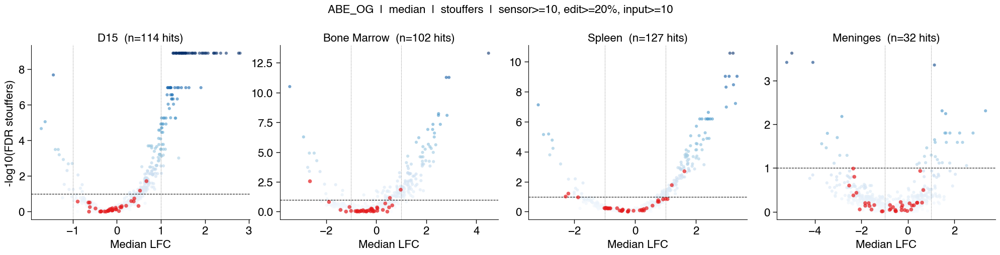

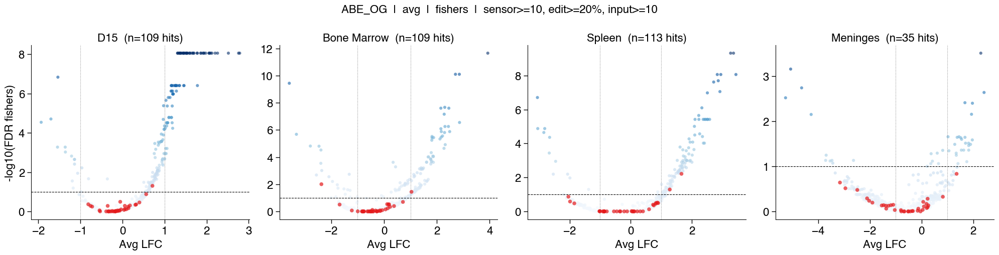

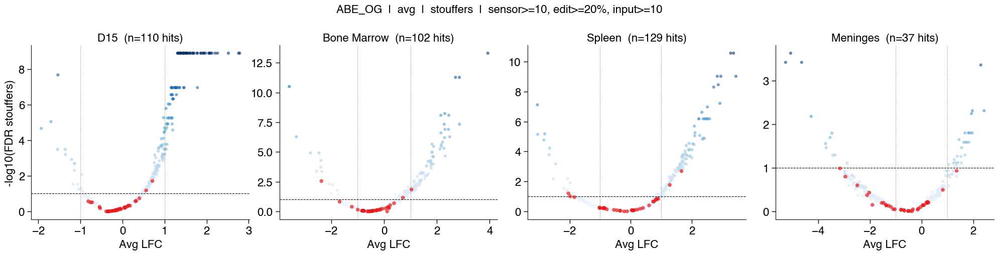

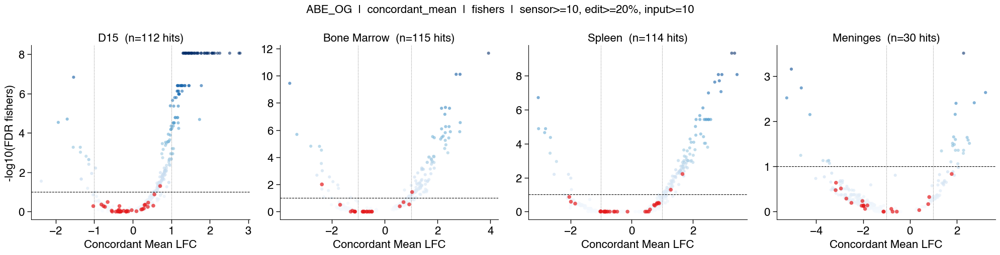

...

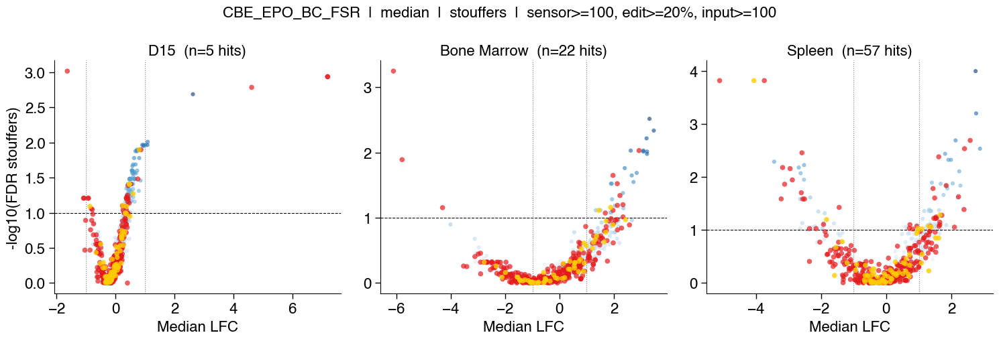

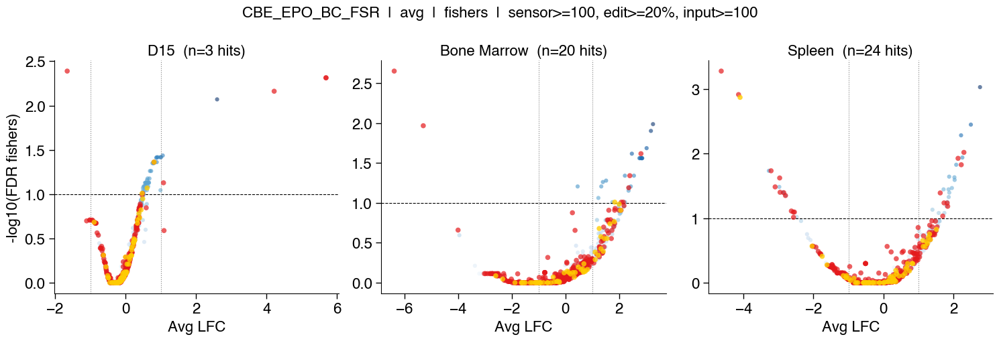

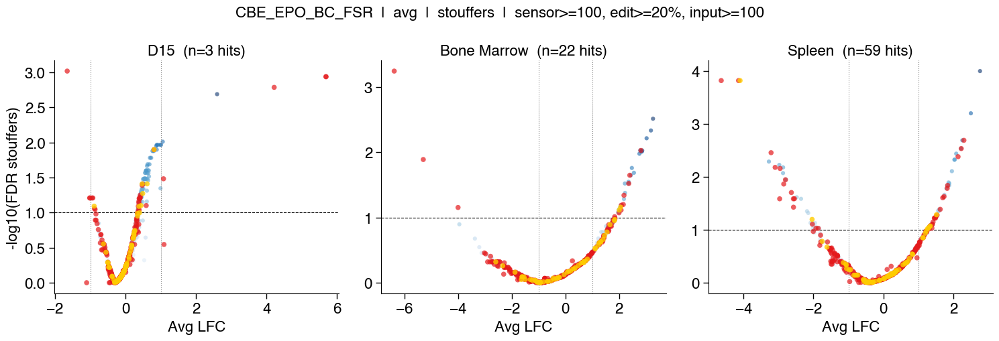

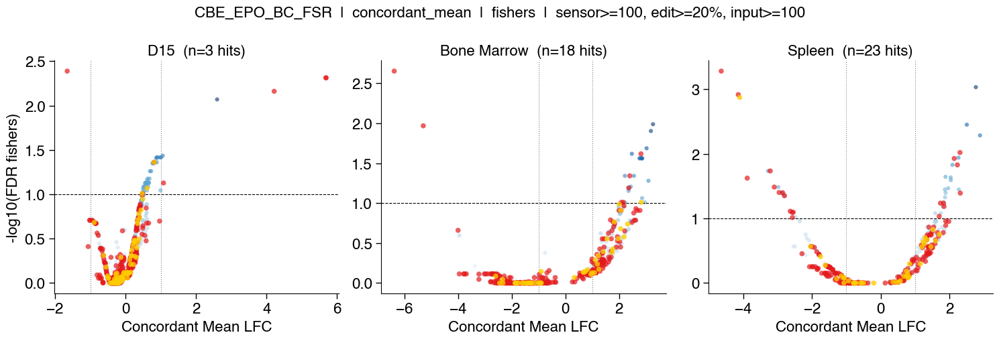

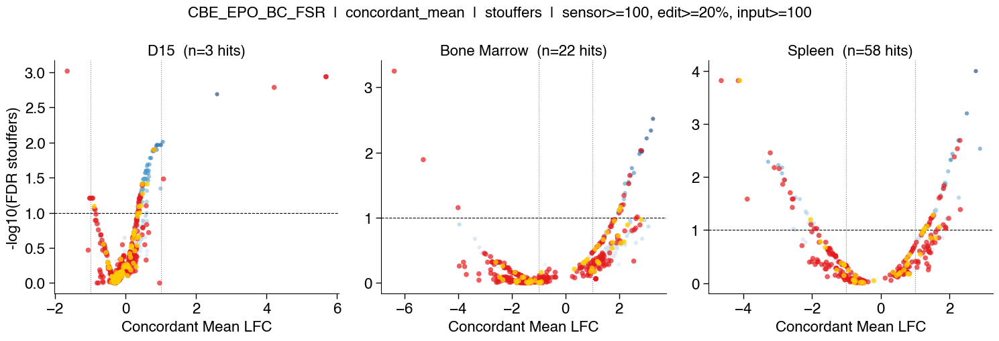

In [ ]:
for screen, conds in [('ABE_OG', conds_og), ('CBE_OG', conds_og)]:
    for effect in ['median', 'avg', 'concordant_mean']:
        for fdr_m in ['fishers', 'stouffers']:
            volcano_plot(dfs[screen], screen, conds, effect=effect, fdr_method=fdr_m, is_og=True)

for screen in ['ABE_EPO_T0', 'CBE_EPO_T0', 'ABE_EPO_BC', 'CBE_EPO_BC', 'ABE_EPO_T0_FSR','CBE_EPO_T0_FSR','ABE_EPO_BC_FSR','CBE_EPO_BC_FSR']:
    if dfs.get(screen) is None: continue
    for effect in ['median', 'avg', 'concordant_mean']:
        for fdr_m in ['fishers', 'stouffers']:
            volcano_plot(dfs[screen], screen, conds_focused, effect=effect, fdr_method=fdr_m, is_og=False)


In [ ]:
for keys in dfs:
    print(keys)

ABE_OG
CBE_OG
ABE_EPO_T0
CBE_EPO_T0
ABE_EPO_BC
CBE_EPO_BC
ABE_BC_T0
CBE_BC_T0
ABE_EPO_T0_FSR
CBE_EPO_T0_FSR
ABE_EPO_BC_FSR
CBE_EPO_BC_FSR
ABE_BC_T0_FSR
CBE_BC_T0_FSR


In [ ]:
def screen_correlation(key1, key2, conditions,
                       effect='median', fdr_method='fishers',
                       fdr_cutoff=0.1, lfc_cutoff=1.0,
                       min_sensor=100, edit_cutoff=20, min_input=100):

    df1 = dfs[key1]; df2 = dfs[key2]
    n = len(conditions)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1: axes = [axes]

    def filter_df(df, cond):
        lfc = f'LFC_{effect}_{cond}'
        fdr = f'FDR_{cond}_{fdr_method}'
        rc  = f'sensor_reads_{cond}'
        ec  = f'target_base_edit_perc_{cond}'
        if lfc not in df.columns or fdr not in df.columns:
            return None
        t = df[df['classification'] == 'targeting guide'].copy()
        input_ok = (t['Input_median'] >= min_input) if 'Input_median' in t.columns else pd.Series(True, index=t.index)
        if rc in t.columns and ec in t.columns:
            ok = input_ok & (t[rc] >= min_sensor) & (t[ec] >= edit_cutoff)
        else:
            ok = input_ok
        return t[ok][['gRNA_id', lfc, fdr]].dropna()

    for k, cond in enumerate(conditions):
        lfc = f'LFC_{effect}_{cond}'
        fdr = f'FDR_{cond}_{fdr_method}'
        ax = axes[k]

        f1 = filter_df(df1, cond)
        f2 = filter_df(df2, cond)
        if f1 is None or f2 is None:
            ax.set_visible(False); continue

        f1 = f1.rename(columns={lfc:'lfc_1', fdr:'fdr_1'})
        f2 = f2.rename(columns={lfc:'lfc_2', fdr:'fdr_2'})
        targ = pd.merge(f1, f2, on='gRNA_id').dropna()

        sig1 = (targ['fdr_1'] < fdr_cutoff) & (targ['lfc_1'].abs() > lfc_cutoff)
        sig2 = (targ['fdr_2'] < fdr_cutoff) & (targ['lfc_2'].abs() > lfc_cutoff)
        same_dir = np.sign(targ['lfc_1']) == np.sign(targ['lfc_2'])

        only1 = sig1 & (~sig2 | (sig2 & ~same_dir))
        only2 = sig2 & (~sig1 | (sig1 & ~same_dir))
        both  = sig1 & sig2 & same_dir

        cats = {
            f'{key1} only': (only1 & ~both,   blues[3]),
            'Both':         (both,             reds[3]),
            f'{key2} only': (only2 & ~both,   greens[3]),
            'Neither':      (~only1 & ~only2 & ~both, 'lightgrey'),
        }

        for lab, (mask, col) in cats.items():
            sub = targ[mask]
            ax.scatter(sub['lfc_1'], sub['lfc_2'], c=col, s=10, alpha=0.6,
                       label=f'{lab} (n={len(sub)})',
                       zorder=1 if lab == 'Neither' else 3)

        rp, _ = scipy.stats.pearsonr(targ['lfc_1'], targ['lfc_2'])
        rs, _ = scipy.stats.spearmanr(targ['lfc_1'], targ['lfc_2'])

        lim = max(targ[['lfc_1','lfc_2']].abs().max().max(), 1) * 1.05
        ax.plot([-lim, lim], [-lim, lim], 'k--', linewidth=0.8)
        ax.axhline(0, color='grey', linewidth=0.5)
        ax.axvline(0, color='grey', linewidth=0.5)

        cond_label = {'bm':'Bone Marrow','spleen':'Spleen','men':'Meninges','d15':'D15'}.get(cond, cond)
        ax.set_title(f'{cond_label}\nRp={rp:.2f}, Rs={rs:.2f}', fontsize=14)
        ax.set_xlabel(f'{key1} LFC', fontsize=14)
        ax.set_ylabel(f'{key2} LFC', fontsize=14)
        ax.legend(frameon=False, fontsize=10)
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(labelsize=13, direction='out', length=6, width=1)

    fig.suptitle(
        f'{key1} vs {key2}  |  effect={effect}  |  FDR ({fdr_method})<{fdr_cutoff}  |  |LFC|>{lfc_cutoff}  |  edit>={edit_cutoff}%',
        fontsize=14, y=1.01
    )

    fig.tight_layout()
    plt.show()

In [ ]:
combs_abe = [
    ('ABE_BC_T0','ABE_BC_T0_FSR'),
    
    ('ABE_EPO_T0', 'ABE_OG'),
    
    ('ABE_EPO_T0_FSR', 'ABE_OG'),
    ('ABE_EPO_T0_FSR', 'ABE_EPO_T0'),
    
    ('ABE_EPO_BC', 'ABE_OG'),
    ('ABE_EPO_BC_FSR', 'ABE_OG'),
    ('ABE_EPO_BC_FSR', 'ABE_EPO_BC'),
]

In [ ]:
combs_cbe = [
    ('CBE_BC_T0','CBE_BC_T0_FSR'),
    
    ('CBE_EPO_T0', 'CBE_OG'),
    
    ('CBE_EPO_T0_FSR', 'CBE_OG'),
    ('CBE_EPO_T0_FSR', 'CBE_EPO_T0'),
    
    ('CBE_EPO_BC', 'CBE_OG'),
    ('CBE_EPO_BC_FSR', 'CBE_OG'),
    ('CBE_EPO_BC_FSR', 'CBE_EPO_BC'),

]

In [ ]:
dfs.keys()

dict_keys(['ABE_OG', 'CBE_OG', 'ABE_EPO_T0', 'CBE_EPO_T0', 'ABE_EPO_BC', 'CBE_EPO_BC', 'ABE_BC_T0', 'CBE_BC_T0', 'ABE_EPO_T0_FSR', 'CBE_EPO_T0_FSR', 'ABE_EPO_BC_FSR', 'CBE_EPO_BC_FSR', 'ABE_BC_T0_FSR', 'CBE_BC_T0_FSR'])

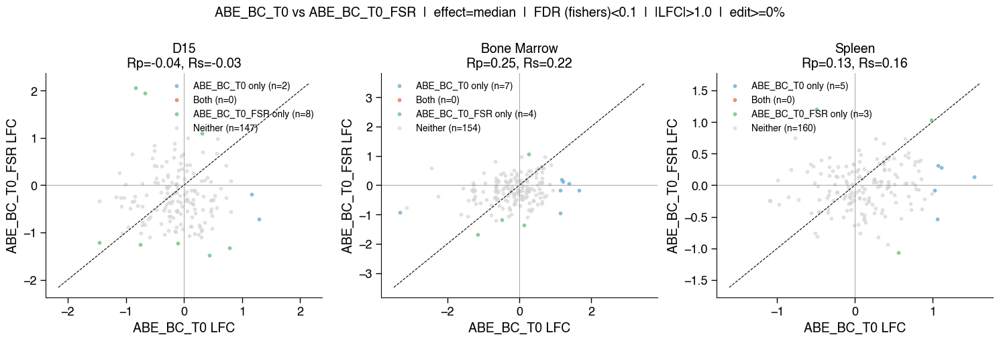

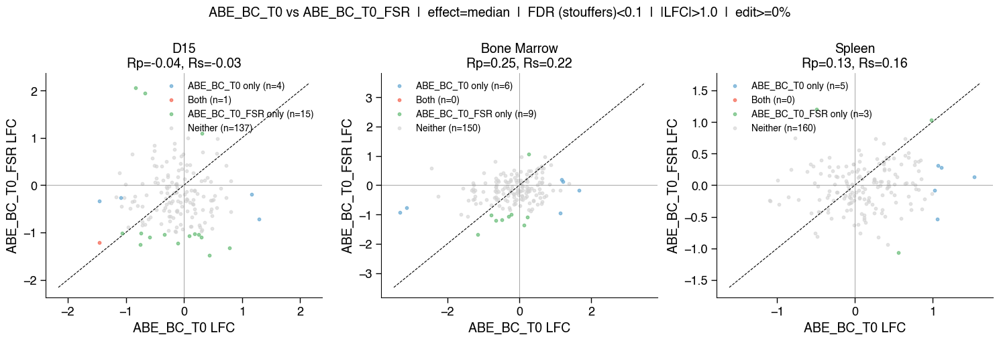

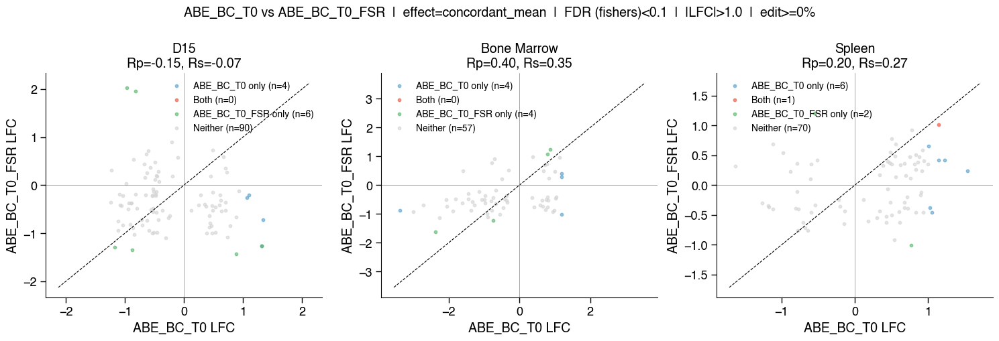

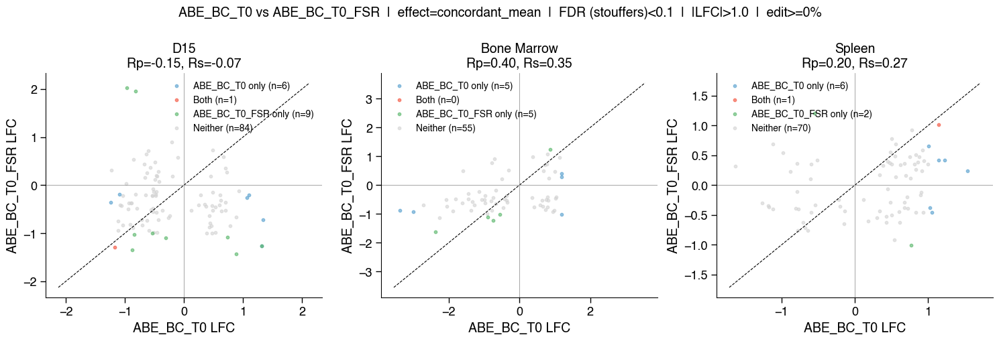

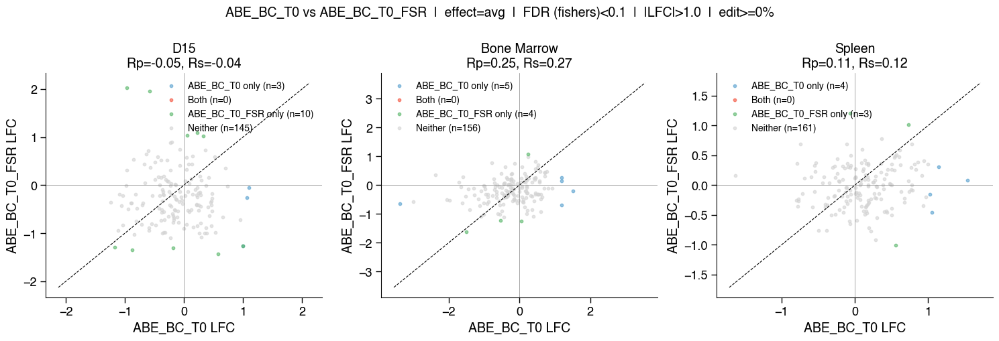

...

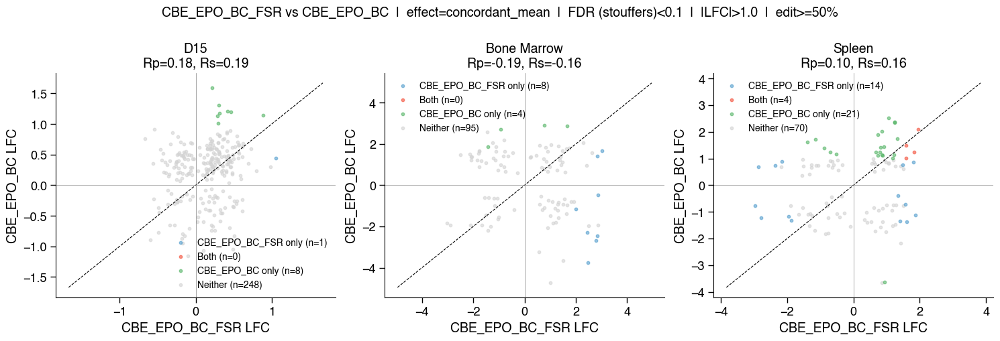

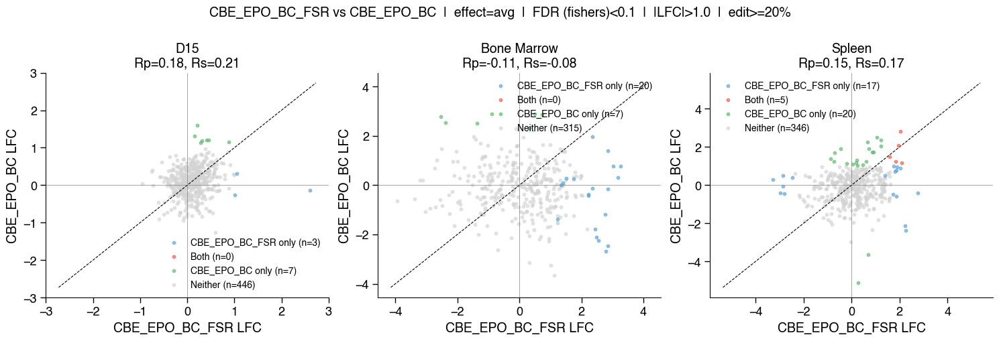

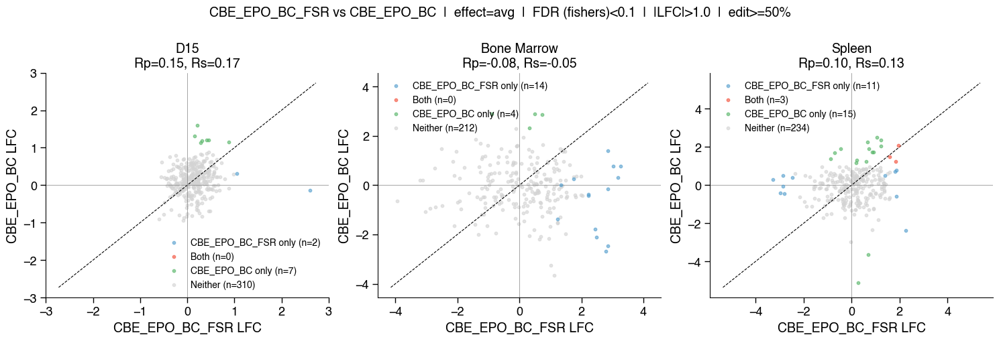

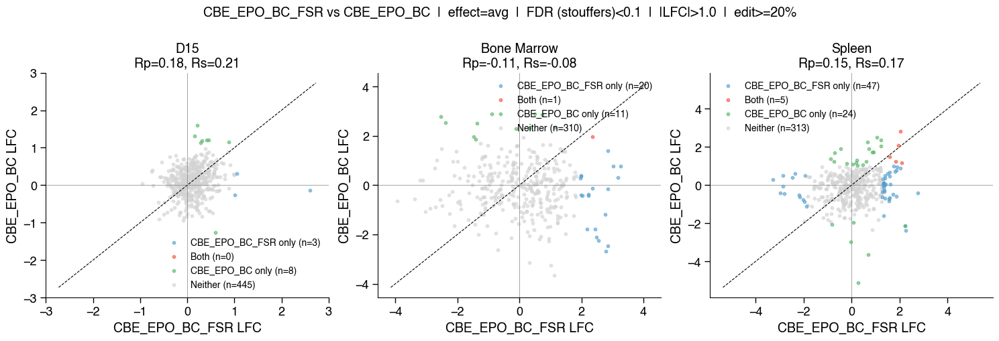

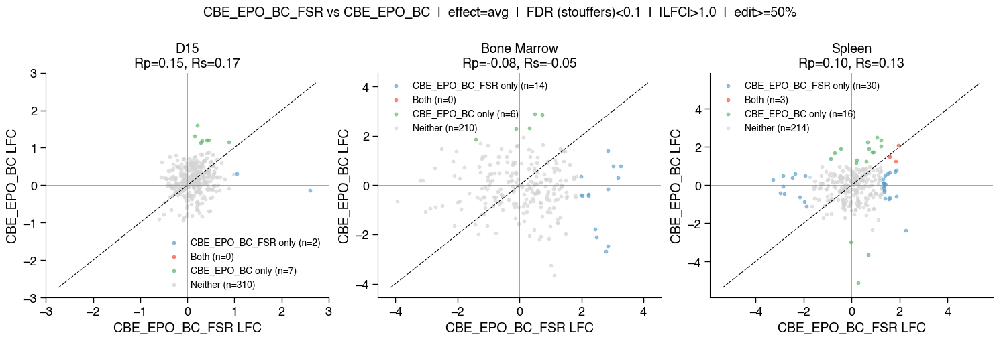

In [ ]:

# pairs that skip editing filter
no_edit_pairs = {('ABE_BC_T0','ABE_BC_T0_FSR'), ('CBE_BC_T0','CBE_BC_T0_FSR')}

effects     = ['median', 'concordant_mean', 'avg']
fdr_methods = ['fishers', 'stouffers']
edit_cuts   = [20, 50]
conds_og      = ['d15', 'bm', 'spleen', 'men']
conds_focused = ['d15', 'bm', 'spleen']

for combs in [combs_abe, combs_cbe]:
    for key1, key2 in combs:
        skip_edit = (key1, key2) in no_edit_pairs or (key2, key1) in no_edit_pairs
        is_og1 = 'OG' in key1
        is_og2 = 'OG' in key2
        min_input  = 10 if (is_og1 or is_og2) else 100
        min_sensor = 10 if (is_og1 or is_og2) else 100
        conds = conds_og if (is_og1 or is_og2) else conds_focused

        for effect in effects:
            for fdr_method in fdr_methods:
                if skip_edit:
                    screen_correlation(key1, key2, conditions=conds,
                                       effect=effect, fdr_method=fdr_method,
                                       fdr_cutoff=0.1, lfc_cutoff=1.0,
                                       min_sensor=min_sensor, edit_cutoff=0,
                                       min_input=min_input)
                else:
                    for edit_cut in edit_cuts:
                        screen_correlation(key1, key2, conditions=conds,
                                           effect=effect, fdr_method=fdr_method,
                                           fdr_cutoff=0.1, lfc_cutoff=1.0,
                                           min_sensor=min_sensor, edit_cutoff=edit_cut,
                                           min_input=min_input)
